# Análise Exploratória de Dados (EDA) — dataset *tiny*
### Projeto 01 — Grupo 03

Objetivo deste notebook (entrega preliminar):

1. **Carregar** os CSVs e perceber o que cada tabela contém;
2. **Validar a integridade** dos dados (nulos, chaves duplicadas, chaves estrangeiras, matriz de distâncias);
3. **Validar as janelas temporais** (recolha e entrega) e ver se cada item é, à partida, possível de servir;
4. **Comparar pesos com capacidades** dos veículos;
5. **Mapear as paragens** (produtores, armazém e locais de entrega).

No fim resumimos o que aprendemos e as decisões de modelação que daqui resultam.
Para comparação, algumas verificações são repetidas para o dataset *small*.

## 1. Setup

In [1]:
import os
import math
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

# Pasta do projeto (funciona a partir de Notebooks/ ou da raiz)
ROOT = os.path.abspath(".." if os.path.exists("../data_tiny") else ".")

# Estilo dos gráficos: paleta categórica validada (azul, laranja, aqua) + tinta neutra
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (10, 5), "font.size": 10, "axes.edgecolor": INK2,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "legend.frameon": False,
    "axes.axisbelow": True,
})
print("Pasta do projeto:", ROOT)

Pasta do projeto: /home/claude/v_csp/IA26_P01_G03


## 2. Carregamento dos dados

Cada dataset é uma pasta com 12 ficheiros CSV (não é preciso base de dados).
Lemos todos para um dicionário `df[nome_da_tabela]`.

In [2]:
TABLES = ["localities", "producers", "products", "collection_centers", "vehicles",
          "customers", "delivery_locations", "orders", "order_items",
          "locations", "distance_matrix", "rules"]

def load(dataset):
    path = os.path.join(ROOT, dataset)
    return {t: pd.read_csv(os.path.join(path, t + ".csv")) for t in TABLES}

df = load("data_tiny")
df_small = load("data_small")

pd.DataFrame({
    "linhas (tiny)": {t: len(df[t]) for t in TABLES},
    "linhas (small)": {t: len(df_small[t]) for t in TABLES},
    "colunas": {t: ", ".join(df[t].columns) for t in TABLES},
})

,linhas (tiny),linhas (small),colunas
localities,49,49,"locality_id, name, municipality, district, lat..."
producers,3,6,"producer_id, name, locality_id, address, phone..."
products,15,31,"product_id, producer_id, name, category, unit,..."
collection_centers,1,1,"center_id, name, locality_id, address, capacit..."
vehicles,2,2,"vehicle_id, plate, center_id, capacity_kg, ref..."
customers,12,21,"customer_id, name, locality_id, phone, email"
delivery_locations,5,7,"delivery_location_id, name, locality_id, addre..."
orders,12,25,"order_id, customer_id, delivery_location_id, o..."
order_items,40,80,"order_item_id, order_id, product_id, quantity,..."
locations,9,14,"location_id, location_type, ref_id, name, muni..."


**O que contém cada tabela**

| Tabela | Conteúdo |
|---|---|
| `localities` | freguesias com município, distrito e coordenadas |
| `producers`, `products` | produtores e os produtos que oferecem (peso unitário) |
| `collection_centers`, `vehicles` | armazém e a frota que lá está sediada (capacidade em kg) |
| `customers`, `delivery_locations` | clientes e locais de entrega (casa, loja, restaurante) |
| `orders`, `order_items` | encomendas e as suas linhas, com as **duas janelas temporais** |
| `locations`, `distance_matrix` | camada de encaminhamento: paragens e distância/tempo entre cada par |
| `rules` | regras do problema (tempos de serviço, 24h no armazém, ...) |

In [3]:
df["rules"]

,rule,value,description
0,start_date,2026-10-30,first day of the planning horizon
1,horizon_days,2,number of days
2,flow,producer>warehouse>delivery_location,every product goes through the warehouse
3,stop_service_min,10,service time at each pickup / delivery stop
4,warehouse_handling_min,15,time to unload (and to load) a vehicle at the ...
5,max_warehouse_dwell_h,24,max time a product stays in the warehouse (arr...
6,window_semantics,service_start,windows constrain when the service STARTS
7,avg_speed_kmh,45.0,used to build duration_min
8,route_factor,1.3,used to build distance_km
9,generator_seed,1,seed that produced this dataset


In [4]:
df["vehicles"]

,vehicle_id,plate,center_id,capacity_kg,refrigerated,avg_speed_kmh
0,1,ZG-06-DP,1,150.0,1,45.0
1,2,TY-74-YA,1,200.0,0,45.0


In [5]:
df["order_items"].head()

,order_item_id,order_id,product_id,quantity,weight_kg,availability_start,availability_end,delivery_start,delivery_end
0,1,1,10,6.3,6.3,2026-10-31 07:30:00,2026-10-31 10:30:00,2026-10-31 10:30:00,2026-10-31 12:45:00
1,2,1,3,3.7,3.7,2026-10-31 08:15:00,2026-10-31 11:15:00,2026-10-31 10:30:00,2026-10-31 12:45:00
2,3,1,15,4.9,4.9,2026-10-31 07:30:00,2026-10-31 10:15:00,2026-10-31 10:30:00,2026-10-31 12:45:00
3,4,1,13,7.1,7.1,2026-10-31 07:15:00,2026-10-31 10:45:00,2026-10-31 10:30:00,2026-10-31 12:45:00
4,5,2,3,1.8,1.8,2026-10-30 07:15:00,2026-10-30 11:15:00,2026-10-31 07:15:00,2026-10-31 10:15:00


## 3. Integridade dos dados

### 3.1 Valores em falta e chaves primárias duplicadas

In [6]:
pk = {"localities": "locality_id", "producers": "producer_id", "products": "product_id",
      "collection_centers": "center_id", "vehicles": "vehicle_id", "customers": "customer_id",
      "delivery_locations": "delivery_location_id", "orders": "order_id",
      "order_items": "order_item_id", "locations": "location_id"}

pd.DataFrame({
    "valores nulos": {t: int(df[t].isna().sum().sum()) for t in TABLES},
    "chaves duplicadas": {t: str(int(df[t][pk[t]].duplicated().sum())) if t in pk else "-" for t in TABLES},
})

,valores nulos,chaves duplicadas
localities,0,0
producers,0,0
products,0,0
collection_centers,0,0
vehicles,0,0
customers,0,0
delivery_locations,0,0
orders,0,0
order_items,0,0
locations,0,0


### 3.2 Chaves estrangeiras (todas as referências apontam para registos que existem?)

In [7]:
fks = [("producers", "locality_id", "localities", "locality_id"),
       ("products", "producer_id", "producers", "producer_id"),
       ("collection_centers", "locality_id", "localities", "locality_id"),
       ("vehicles", "center_id", "collection_centers", "center_id"),
       ("customers", "locality_id", "localities", "locality_id"),
       ("delivery_locations", "locality_id", "localities", "locality_id"),
       ("orders", "customer_id", "customers", "customer_id"),
       ("orders", "delivery_location_id", "delivery_locations", "delivery_location_id"),
       ("order_items", "order_id", "orders", "order_id"),
       ("order_items", "product_id", "products", "product_id"),
       ("distance_matrix", "origin_location_id", "locations", "location_id"),
       ("distance_matrix", "destination_location_id", "locations", "location_id")]

def check_fks(d):
    rows = []
    for child, col, parent, pcol in fks:
        missing = ~d[child][col].isin(d[parent][pcol])
        rows.append({"tabela": child, "coluna": col, "referencia": f"{parent}.{pcol}",
                     "referências inválidas": int(missing.sum())})
    return pd.DataFrame(rows)

check_fks(df)

,tabela,coluna,referencia,referências inválidas
0,producers,locality_id,localities.locality_id,0
1,products,producer_id,producers.producer_id,0
2,collection_centers,locality_id,localities.locality_id,0
3,vehicles,center_id,collection_centers.center_id,0
4,customers,locality_id,localities.locality_id,0
5,delivery_locations,locality_id,localities.locality_id,0
6,orders,customer_id,customers.customer_id,0
7,orders,delivery_location_id,delivery_locations.delivery_location_id,0
8,order_items,order_id,orders.order_id,0
9,order_items,product_id,products.product_id,0


### 3.3 Camada de encaminhamento: `locations` e `distance_matrix`

Verificamos que:
- cada paragem de `locations` tem as coordenadas da freguesia da entidade correspondente;
- a matriz tem **todos os pares ordenados** de paragens, é **simétrica**;
- `distance_km` = distância em linha reta (haversine) × 1,3 e `duration_min` = distância a 45 km/h (como dizem as regras).

In [8]:
def check_routing_layer(d):
    loc, dm = d["locations"], d["distance_matrix"]
    # coordenadas de cada paragem = coordenadas da freguesia da entidade
    src = {"producer": ("producers", "producer_id"), "collection_center": ("collection_centers", "center_id"),
           "delivery_location": ("delivery_locations", "delivery_location_id")}
    lat = d["localities"].set_index("locality_id")
    bad_coords = 0
    for r in loc.itertuples():
        table, key = src[r.location_type]
        ent = d[table].set_index(key).loc[r.ref_id]
        l = lat.loc[ent.locality_id]
        bad_coords += abs(l.latitude - r.latitude) > 1e-6 or abs(l.longitude - r.longitude) > 1e-6

    n = len(loc)
    pairs = set(zip(dm.origin_location_id, dm.destination_location_id))
    sym = dm.merge(dm, left_on=["origin_location_id", "destination_location_id"],
                   right_on=["destination_location_id", "origin_location_id"])
    c = loc.set_index("location_id")[["latitude", "longitude"]]

    def haversine(a, b):
        la1, lo1, la2, lo2 = map(math.radians, [*c.loc[a], *c.loc[b]])
        h = math.sin((la2 - la1) / 2) ** 2 + math.cos(la1) * math.cos(la2) * math.sin((lo2 - lo1) / 2) ** 2
        return 2 * 6371 * math.asin(math.sqrt(h))

    est_km = [haversine(a, b) * 1.3 for a, b in zip(dm.origin_location_id, dm.destination_location_id)]
    return pd.Series(dtype=object, data={
        "paragens": n,
        "paragens com coordenadas erradas": int(bad_coords),
        "pares na matriz": len(pairs),
        "pares esperados n(n-1)": n * (n - 1),
        "pares não simétricos": int(((sym.distance_km_x - sym.distance_km_y).abs() > 1e-9).sum()),
        "erro máx. distância vs haversine×1,3 (km)": round(max(abs(e - k) for e, k in zip(est_km, dm.distance_km)), 3),
        "erro máx. duração vs 45 km/h (min)": round((dm.duration_min - dm.distance_km / 45 * 60).abs().max(), 3),
    })

pd.DataFrame({"tiny": check_routing_layer(df), "small": check_routing_layer(df_small)})

,tiny,small
paragens,9,14
paragens com coordenadas erradas,0,0
pares na matriz,72,182
pares esperados n(n-1),72,182
pares não simétricos,0,0
"erro máx. distância vs haversine×1,3 (km)",0.005,0.005
erro máx. duração vs 45 km/h (min),0.053,0.053


In [9]:
# Matriz de tempos de viagem (min) do tiny, para ter uma ideia das distâncias
names = df["locations"].set_index("location_id")["name"]
tm = df["distance_matrix"].pivot(index="origin_location_id", columns="destination_location_id",
                                 values="duration_min").rename(index=names, columns=names)
tm.round(0)

destination_location_id,Hortas Valente,Campos Leite,Horta Morais,Centro de Recolha 1,Loja 1,Casa 2,Casa 3,Casa 4,Loja 5
origin_location_id,,,,,,,,,
Hortas Valente,NaN,31.0,52.0,41.0,18.0,89.0,20.0,52.0,20.0
Campos Leite,31.0,NaN,35.0,50.0,41.0,95.0,48.0,73.0,48.0
Horta Morais,52.0,35.0,NaN,39.0,49.0,70.0,58.0,67.0,58.0
Centro de Recolha 1,41.0,50.0,39.0,NaN,25.0,48.0,31.0,28.0,31.0
Loja 1,18.0,41.0,49.0,25.0,NaN,72.0,9.0,35.0,9.0
Casa 2,89.0,95.0,70.0,48.0,72.0,NaN,75.0,48.0,75.0
Casa 3,20.0,48.0,58.0,31.0,9.0,75.0,NaN,34.0,0.0
Casa 4,52.0,73.0,67.0,28.0,35.0,48.0,34.0,NaN,34.0
Loja 5,20.0,48.0,58.0,31.0,9.0,75.0,0.0,34.0,NaN


Nota: no *tiny* a **Casa 3** e a **Loja 5** estão na mesma freguesia, por isso têm as mesmas
coordenadas (distância 0). No *small* o produtor **Courela Carvalho** fica no mesmo sítio que o armazém.
Não são erros: é uma consequência de as coordenadas serem as da freguesia.

## 4. Janelas temporais

Cada linha de encomenda (`order_items`) tem duas janelas:
- `availability_start/end` — quando o produto pode ser **recolhido** no produtor;
- `delivery_start/end` — quando tem de ser **entregue** no local escolhido pelo cliente.

Segundo as regras, as janelas limitam o **início do serviço** (`window_semantics = service_start`).
Juntamos as tabelas para ter, em cada item, o produtor, o peso e o local de entrega.

In [10]:
TIME_COLS = ["availability_start", "availability_end", "delivery_start", "delivery_end"]

def items_table(d):
    it = d["order_items"].copy()
    for col in TIME_COLS:
        it[col] = pd.to_datetime(it[col])
    it = it.merge(d["products"][["product_id", "producer_id", "name", "unit_weight_kg"]], on="product_id")
    it = it.merge(d["orders"][["order_id", "delivery_location_id"]], on="order_id")
    it["pickup_day"] = it.availability_start.dt.date
    it["delivery_day"] = it.delivery_start.dt.date
    return it

items = items_table(df)
items_small = items_table(df_small)

def window_checks(it):
    per_order = it.groupby("order_id")
    return pd.Series({
        "itens": len(it),
        "janelas com início >= fim": int(((it.availability_start >= it.availability_end) |
                                          (it.delivery_start >= it.delivery_end)).sum()),
        "recolha a atravessar a meia-noite": int((it.availability_start.dt.date != it.availability_end.dt.date).sum()),
        "entrega começa antes da disponibilidade": int((it.delivery_start < it.availability_start).sum()),
        "peso != quantidade × peso unitário": int(((it.quantity * it.unit_weight_kg - it.weight_kg).abs() > 0.05).sum()),
        "encomendas com janelas de entrega diferentes": int((per_order.delivery_start.nunique() > 1).sum()),
        "encomendas recolhidas em dias diferentes": int((per_order.pickup_day.nunique() > 1).sum()),
        "encomendas entregues no mesmo dia": int((per_order.first().pickup_day == per_order.first().delivery_day).sum()),
        "encomendas entregues no dia seguinte": int((per_order.first().pickup_day < per_order.first().delivery_day).sum()),
    })

pd.DataFrame({"tiny": window_checks(items), "small": window_checks(items_small)})

,tiny,small
itens,40,80
janelas com início >= fim,0,0
recolha a atravessar a meia-noite,0,0
entrega começa antes da disponibilidade,0,0
peso != quantidade × peso unitário,0,0
encomendas com janelas de entrega diferentes,0,0
encomendas recolhidas em dias diferentes,0,0
encomendas entregues no mesmo dia,9,19
encomendas entregues no dia seguinte,3,6


Todas as janelas são coerentes. Duas observações importantes para a modelação:
- **todos os itens de uma encomenda partilham a mesma janela de entrega** e são recolhidos no mesmo dia;
- uma parte das encomendas é **entregue no dia seguinte**: os produtos passam a noite no armazém
  e aí entra a regra das **24 h no armazém** (`max_warehouse_dwell_h`).

### 4.1 Cada item é possível de servir sozinho?

Antes de pensar em rotas, verificamos o caso mais favorável para cada item: um veículo sai do armazém,
recolhe o item no início da janela, volta ao armazém (descarga 15 min + carga 15 min) e vai entregá-lo.
Se mesmo assim chegar depois de a janela de entrega fechar, o item é impossível.

In [11]:
def best_case(d, it):
    rules = dict(zip(d["rules"].rule, d["rules"].value))
    service, handling = float(rules["stop_service_min"]), float(rules["warehouse_handling_min"])
    loc = d["locations"]
    ploc = dict(zip(loc[loc.location_type == "producer"].ref_id, loc[loc.location_type == "producer"].location_id))
    dloc = dict(zip(loc[loc.location_type == "delivery_location"].ref_id,
                    loc[loc.location_type == "delivery_location"].location_id))
    W = loc[loc.location_type == "collection_center"].location_id.iloc[0]
    tt = {(a, b): t for a, b, t in zip(d["distance_matrix"].origin_location_id,
                                         d["distance_matrix"].destination_location_id,
                                         d["distance_matrix"].duration_min)}
    out = it.copy()
    p = out.producer_id.map(ploc)
    q = out.delivery_location_id.map(dloc)
    to_wh = pd.Series([tt[x, W] for x in p], index=out.index)          # produtor -> armazém
    to_client = pd.Series([tt[W, y] for y in q], index=out.index)      # armazém -> cliente
    earliest_delivery = out.availability_start + pd.to_timedelta(
        service + to_wh + 2 * handling + to_client, unit="min")
    out["folga (min)"] = (out.delivery_end - earliest_delivery).dt.total_seconds() / 60
    return out

bc = best_case(df, items)
bc_small = best_case(df_small, items_small)
pd.DataFrame({
    "tiny": bc["folga (min)"].describe().round(0),
    "small": bc_small["folga (min)"].describe().round(0),
}).rename_axis("folga no melhor caso (min)")

,tiny,small
folga no melhor caso (min),,
count,40.0,80.0
mean,534.0,599.0
std,554.0,521.0
min,158.0,111.0
25%,193.0,256.0
50%,233.0,344.0
75%,591.0,715.0
max,1598.0,1598.0


A folga mínima é positiva: **nenhum item é impossível à partida**. O que torna o problema difícil
é servir **todos ao mesmo tempo** com só dois veículos.

### 4.2 Lotes de recolha: as janelas dos itens de um produtor num dia cruzam-se?

Se as janelas de todos os itens de um produtor, num dia, tiverem uma interseção comum, então **uma só
visita** chega para recolher tudo. Isto permite agrupar os itens em **lotes (produtor, dia)**.

In [12]:
def lots(it):
    g = it.groupby(["producer_id", "pickup_day"])
    t = g.agg(itens=("order_item_id", "count"), kg=("weight_kg", "sum"),
              inicio_comum=("availability_start", "max"), fim_comum=("availability_end", "min"))
    t["interseção (min)"] = (t.fim_comum - t.inicio_comum).dt.total_seconds() / 60
    t["kg"] = t.kg.round(1)
    return t

lots_tiny = lots(items)
lots_tiny

itens    kg        inicio_comum           fim_comum  interseção (min)
producer_id pickup_day                                                                       
1           2026-10-30      8  52.0 2026-10-30 09:30:00 2026-10-30 09:45:00              15.0
            2026-10-31      5  41.1 2026-10-31 09:00:00 2026-10-31 11:15:00             135.0
2           2026-10-30      9  77.6 2026-10-30 09:00:00 2026-10-30 10:30:00              90.0
            2026-10-31      5  29.9 2026-10-31 08:15:00 2026-10-31 10:00:00             105.0
3           2026-10-30      7  37.3 2026-10-30 08:00:00 2026-10-30 09:45:00             105.0
            2026-10-31      6  32.1 2026-10-31 07:45:00 2026-10-31 09:45:00             120.0

In [13]:
lots_small = lots(items_small)
print("small: lotes com interseção vazia =", int((lots_small["interseção (min)"] < 0).sum()), "de", len(lots_small))
print("small: interseção mínima =", lots_small["interseção (min)"].min(), "min")

small: lotes com interseção vazia = 0 de 12
small: interseção mínima = 90.0 min


Em ambos os datasets **todas as interseções são não vazias** (no tiny, a mais apertada é de 15 min).
Por isso, no modelo, cada lote (produtor, dia) é recolhido numa só visita.

O gráfico seguinte mostra as janelas comuns de recolha de cada lote e as janelas de entrega de cada
encomenda do tiny, ao longo dos dois dias.

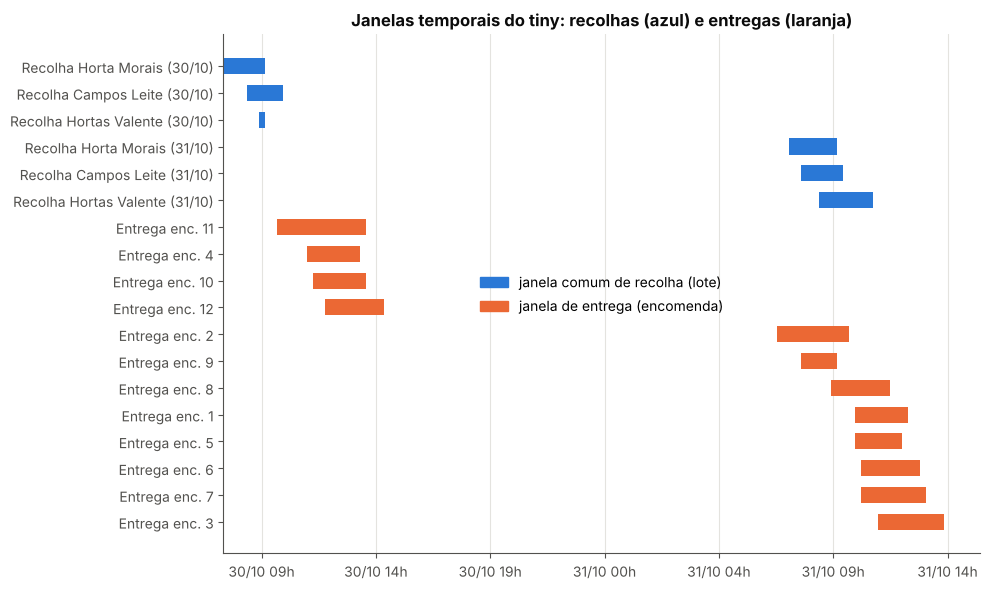

In [14]:
orders_w = items.groupby("order_id").agg(start=("delivery_start", "first"), end=("delivery_end", "first"))
pnames = df["producers"].set_index("producer_id")["name"]

rows = [(f"Recolha {pnames[p]} ({d:%d/%m})", r.inicio_comum, r.fim_comum, BLUE)
        for (p, d), r in lots_tiny.sort_values("inicio_comum").iterrows()]
rows += [(f"Entrega enc. {o}", r.start, r.end, ORANGE) for o, r in orders_w.sort_values("start").iterrows()]

fig, ax = plt.subplots(figsize=(10, 6))
for y, (label, s, e, color) in enumerate(rows):
    ax.barh(y, mdates.date2num(e) - mdates.date2num(s), left=mdates.date2num(s), height=0.6, color=color)
ax.set_yticks(range(len(rows)), [r[0] for r in rows])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh"))
ax.grid(axis="y", visible=False)
ax.set_title("Janelas temporais do tiny: recolhas (azul) e entregas (laranja)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
          labels=["janela comum de recolha (lote)", "janela de entrega (encomenda)"], loc="center")
plt.tight_layout()
plt.show()

As recolhas acontecem sempre de manhã (entre as 06:45 e as 12:15) e as entregas do próprio dia
a partir das 10:15. As entregas do dia seguinte (encomendas 2, 8 e 9) acontecem logo na manhã de 31/10,
**ao mesmo tempo** que as recolhas desse dia: um veículo não consegue fazer tudo.

## 5. Pesos vs. capacidades

In [15]:
def weights(d, it):
    cap = d["vehicles"].capacity_kg
    per_day = it.groupby("pickup_day").weight_kg.sum()
    return pd.Series({
        "peso total (kg)": round(it.weight_kg.sum(), 1),
        "capacidade da frota (kg)": cap.sum(),
        "maior encomenda (kg)": round(it.groupby("order_id").weight_kg.sum().max(), 1),
        "maior lote (kg)": round(it.groupby(["producer_id", "pickup_day"]).weight_kg.sum().max(), 1),
        "menor veículo (kg)": cap.min(),
        "recolhido por dia, máx. (kg)": round(per_day.max(), 1),
    })

pd.DataFrame({"tiny": weights(df, items), "small": weights(df_small, items_small)})

,tiny,small
peso total (kg),270.0,580.0
capacidade da frota (kg),350.0,550.0
maior encomenda (kg),51.1,38.4
maior lote (kg),77.6,120.5
menor veículo (kg),150.0,250.0
"recolhido por dia, máx. (kg)",166.9,338.7


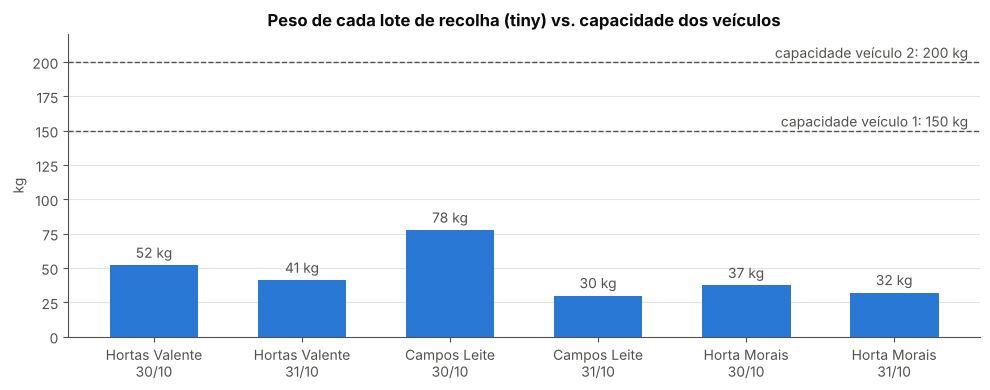

In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
labels = [f"{pnames[p]}\n{d:%d/%m}" for p, d in lots_tiny.index]
ax.bar(range(len(lots_tiny)), lots_tiny.kg, color=BLUE, width=0.6)
for i, v in enumerate(lots_tiny.kg):
    ax.text(i, v + 3, f"{v:.0f} kg", ha="center", va="bottom", color=INK2)
for _, v in df["vehicles"].iterrows():
    ax.axhline(v.capacity_kg, color=INK2, linestyle="--", linewidth=1)
    ax.text(len(lots_tiny) - 0.5, v.capacity_kg + 3, f"capacidade veículo {v.vehicle_id}: {v.capacity_kg:.0f} kg",
            ha="right", color=INK2)
ax.set_xticks(range(len(lots_tiny)), labels)
ax.set_ylabel("kg")
ax.set_ylim(0, 220)
ax.set_title("Peso de cada lote de recolha (tiny) vs. capacidade dos veículos")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

- Qualquer lote ou encomenda cabe sozinho em qualquer veículo.
- No tiny, o peso total (270 kg) cabe na frota (350 kg); no small o peso total (580 kg) é **maior**
  do que a frota (550 kg), mas está distribuído por dois dias, por isso também é possível.
- A capacidade **não é a restrição mais difícil**: são as janelas temporais e as distâncias.

## 6. Mapa das paragens

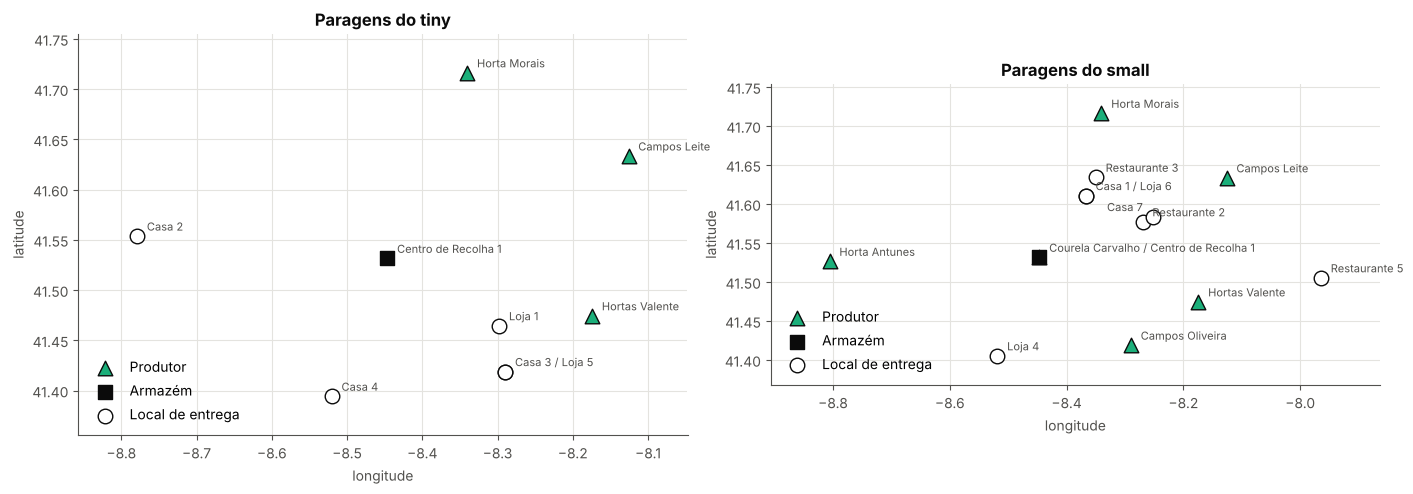

In [17]:
def place_labels(ax, points):
    # Escreve cada nome junto ao seu ponto, na primeira posição que não tapa os anteriores.
    renderer = ax.figure.canvas.get_renderer()
    placed = []
    spots = [(7, 4, "left"), (7, -12, "left"), (-7, 4, "right"), (-7, -12, "right"),
             (7, 15, "left"), (-7, 15, "right"), (7, -23, "left"), (-7, -23, "right")]
    for x, y, text in points:
        for dx, dy, ha in spots:
            a = ax.annotate(text, (x, y), xytext=(dx, dy), textcoords="offset points",
                            ha=ha, fontsize=8, color=INK2)
            box = a.get_window_extent(renderer).expanded(1.05, 1.15)
            if not any(box.overlaps(b) for b in placed):
                placed.append(box)
                break
            a.remove()
        else:                                              # sem espaço livre: posição por omissão
            a = ax.annotate(text, (x, y), xytext=spots[0][:2], textcoords="offset points",
                            fontsize=8, color=INK2)


def stop_points(loc):
    # (lon, lat, nome) por coordenada; paragens no mesmo sítio ficam com um só rótulo.
    names = {}
    for r in loc.itertuples():
        names.setdefault((r.longitude, r.latitude), []).append(r.name)
    return [(x, y, " / ".join(n)) for (x, y), n in names.items()]


def plot_stops(d, title, ax):
    loc = d["locations"]
    styles = {"producer": ("^", AQUA, "Produtor"), "collection_center": ("s", INK, "Armazém"),
              "delivery_location": ("o", "white", "Local de entrega")}
    for typ, (marker, color, label) in styles.items():
        s = loc[loc.location_type == typ]
        ax.scatter(s.longitude, s.latitude, marker=marker, s=110, c=color, edgecolors=INK,
                   linewidths=1, label=label, zorder=3)
    ax.set_aspect(1 / math.cos(math.radians(41.5)))
    ax.margins(0.12)
    ax.set_xlabel("longitude")
    ax.set_ylabel("latitude")
    ax.set_title(title)
    ax.legend(loc="lower left")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_stops(df, "Paragens do tiny", axes[0])
plot_stops(df_small, "Paragens do small", axes[1])
plt.tight_layout()
place_labels(axes[0], stop_points(df["locations"]))
place_labels(axes[1], stop_points(df_small["locations"]))
plt.show()

Os produtores estão espalhados pelo distrito: no small, por exemplo, Esposende (oeste) e Vieira do Minho
(este) ficam a cerca de **100 minutos** um do outro. Como as janelas de recolha são todas de manhã,
o mesmo veículo não consegue visitar todos os produtores no mesmo dia: os veículos têm de **dividir
o território**.

## 7. Conclusões da EDA

| O que observámos | Consequência para o modelo |
|---|---|
| Dados íntegros: sem nulos, sem chaves duplicadas, todas as referências válidas | Podemos carregar os CSVs diretamente, sem limpeza |
| Matriz completa, simétrica, = haversine × 1,3 e 45 km/h | Usamos a matriz tal como está (distância em km = custo) |
| As janelas dos itens de um produtor num dia cruzam-se sempre | Agrupamos os itens em **lotes (produtor, dia)**, recolhidos numa só visita |
| Itens de uma encomenda: mesma janela de entrega e mesmo dia de recolha | Uma entrega por encomenda e por veículo |
| Algumas encomendas são entregues no dia seguinte | A regra das **24 h no armazém** tem de ser verificada |
| Nenhum item é impossível sozinho e a capacidade chega | A dificuldade está em **combinar** janelas e distâncias com 2 veículos |
| Produtores muito afastados entre si | Os veículos têm de dividir os produtores: a atribuição é a decisão crítica |